# Logística en Baja California
Contexto del Negocio: Acaban de ser contratados como Científicos de Datos para una nueva startup de logística (tipo Mercado Libre / Uber) que está arrancando operaciones en el estado de Baja California. Les han entregado el archivo logistica_baja_california.csv:

,Latitud,Longitud,Tipo_Solicitud
0,32.520796,-116.992084,Recoleccion
1,32.566198,-117.046102,Recoleccion
2,32.461507,-117.062417,Viaje_Pasajero
3,32.510667,-117.023516,Viaje_Pasajero
4,32.498468,-117.019210,Viaje_Pasajero


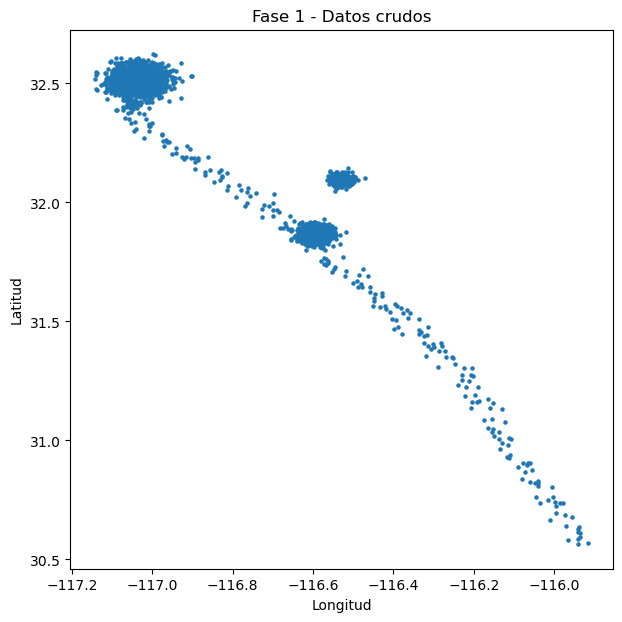

array([[ 0.88335238, -0.73514142],
       [ 1.00618974, -0.94540065],
       [ 0.72294016, -1.00890342],
       [ 0.85594675, -0.85748798],
       [ 0.82294302, -0.84072749]])

In [11]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

df = pd.read_csv("../datasets/logistica_baja_california.csv")
display(df.head())

# Fase 1: datos crudos (Longitud en X, Latitud en Y)
plt.figure(figsize=(7, 7))
plt.scatter(df['Longitud'], df['Latitud'], s=5)
plt.xlabel('Longitud')
plt.ylabel('Latitud')
plt.title('Fase 1 - Datos crudos')
plt.show()

# Escalado: columna 0 = Latitud, columna 1 = Longitud
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[['Latitud', 'Longitud']])
display(X_scaled[:5])

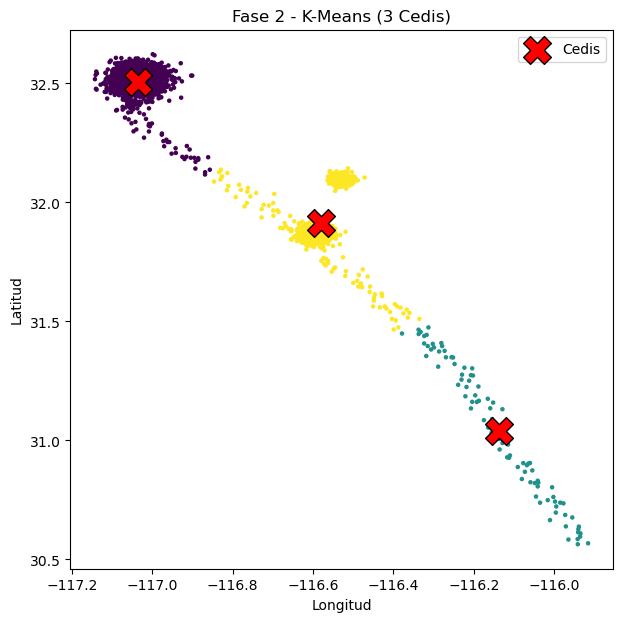

Centros de los clústeres (Cedis):
     Latitud    Longitud
0  32.506316 -117.034964
1  31.040540 -116.138027
2  31.912348 -116.580728
0    1611
1      95
2    1394
Name: count, dtype: int64


In [12]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_scaled)

# Regresar los centros a grados para graficarlos sobre el mapa
centros_reales = scaler.inverse_transform(kmeans.cluster_centers_)  # [Latitud, Longitud]

plt.figure(figsize=(7, 7))
plt.scatter(df['Longitud'], df['Latitud'], c=kmeans.labels_, s=5, cmap='viridis')
plt.scatter(centros_reales[:, 1], centros_reales[:, 0], c='red', marker='X', s=400, edgecolors='black', label='Cedis')
plt.xlabel('Longitud')
plt.ylabel('Latitud')
plt.title('Fase 2 - K-Means (3 Cedis)')
plt.legend()
plt.show()

print("Centros de los clústeres (Cedis):")
print(pd.DataFrame(centros_reales, columns=['Latitud', 'Longitud']))
print(pd.Series(kmeans.labels_).value_counts().sort_index())

### Análisis — Fase 2
- **Algoritmo:** K-Means, porque minimiza la distancia (cuadrática) de cada punto a su centroide, que es justo el "centro geográfico de la demanda".
- **¿Dónde colocó los Cedis?** Uno en Tijuana (~32.51, -117.03), uno cerca de Ensenada (~31.91, -116.58) y uno en medio de la nada al sur (~31.04, -116.14), entre Ensenada y San Quintín.
- **¿Hacen sentido?** Los dos primeros sí; el tercero no: queda en una zona rural casi sin demanda (solo ~95 puntos), y Ensenada y el Valle de Guadalupe quedan compartiendo un solo Cedis.
- **¿Por qué?** K-Means obliga a que **todos** los puntos pertenezcan a un clúster y el centroide es un **promedio**, así que es muy sensible a los outliers: los puntos rurales dispersos del sur "jalan" un centroide hacia ellos. Además asume clústeres esféricos de tamaño parecido y no tiene concepto de ruido.

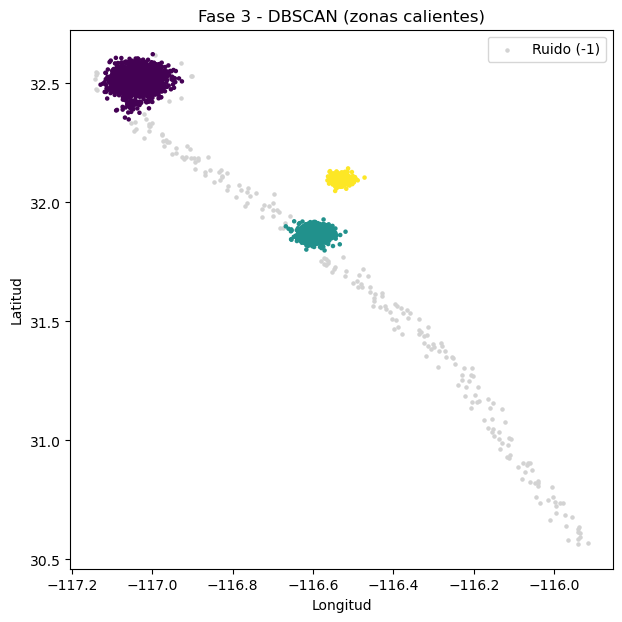

-1     221
 0    1562
 1    1017
 2     300
Name: count, dtype: int64
           Latitud    Longitud
cluster                       
-1       31.563120 -116.428279
 0       32.514223 -117.037489
 1       31.867275 -116.595452
 2       32.097406 -116.530663


In [13]:
from sklearn.cluster import DBSCAN

# eps en unidades escaladas; min_samples=10 exige zonas densas
db = DBSCAN(eps=0.08, min_samples=10).fit(X_scaled)
etiquetas = db.labels_

ruido = etiquetas == -1
plt.figure(figsize=(7, 7))
plt.scatter(df.loc[ruido, 'Longitud'], df.loc[ruido, 'Latitud'], c='lightgray', s=5, label='Ruido (-1)')
plt.scatter(df.loc[~ruido, 'Longitud'], df.loc[~ruido, 'Latitud'], c=etiquetas[~ruido], s=5, cmap='viridis')
plt.xlabel('Longitud')
plt.ylabel('Latitud')
plt.title('Fase 3 - DBSCAN (zonas calientes)')
plt.legend()
plt.show()

print(pd.Series(etiquetas).value_counts().sort_index())
print(df.assign(cluster=etiquetas).groupby('cluster')[['Latitud', 'Longitud']].median())

### Análisis — Fase 3
- **¿Usaron el mismo algoritmo que en la misión anterior?** No. Usamos DBSCAN (clustering por densidad) para encontrar dónde se concentra realmente la demanda.
- **¿De no ser así, por qué se comportaron diferentes?** K-Means asigna **todos** los puntos al centroide más cercano, así que los ranchos aislados distorsionan los centros. DBSCAN agrupa solo puntos con suficientes vecinos dentro de un radio `eps` y marca los puntos dispersos como ruido (-1), así que las zonas rurales quedan descartadas y no afectan a las manchas urbanas.
- **¿A qué ciudades reales corresponden las 3 manchas urbanas?** Tijuana (~32.51, -117.04), Ensenada (~31.87, -116.60) y el Valle de Guadalupe (~32.10, -116.53). Los puntos grises son la carretera y las zonas rurales del sur (ruido).